# TP 2 — Apprentissage profond avec TensorFlow / Keras
## Exercice 2 : Classification d'images avec Fashion-MNIST
Module : Technologies IA — ENSA Fès — Pr. Youness IDRISSI KHAMLICHI

## Chargement via Keras

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

tf.random.set_seed(42)
tf.keras.utils.set_random_seed(42)

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau',
               'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

## Étape 1 — Exploration du jeu de données
### A. Dimensions et types

In [2]:
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Type des pixels :", X_train.dtype, "| min :", X_train.min(), "| max :", X_train.max())
print("Répartition des classes (train) :", np.bincount(y_train))

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type des pixels : uint8 | min : 0 | max : 255
Répartition des classes (train) : [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


### B. Visualisation d'exemples

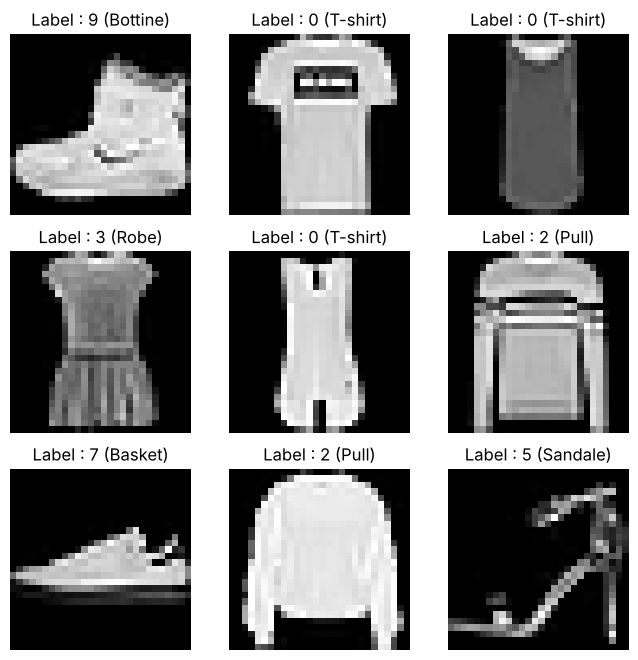

In [3]:
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]} ({class_names[y_train[i]]})")
    plt.axis('off')
plt.show()

### Réponse
**Nature des données et taille des images** : 70 000 images (60 000 train / 10 000 test) en niveaux de gris de 28 × 28 pixels, codées en `uint8` (0–255), un seul canal. Les 10 classes sont parfaitement équilibrées (6 000 images chacune en entraînement). Les objets sont centrés sur fond noir, mais la faible résolution efface les détails : certaines classes se ressemblent fortement (T-shirt / chemise / pull / manteau, sandale / basket / bottine), ce qui rend le problème plus difficile que MNIST.

## Étape 2 — Prétraitement des données

In [4]:
from tensorflow.keras.utils import to_categorical

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Exemple de label :", y_train[0], "->", y_train_cat[0])

Exemple de label : 9 -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


### Réponses
1. **Normaliser les images** : ramener les pixels dans [0, 1] met toutes les entrées à la même échelle que les poids, stabilise les gradients, évite la saturation des activations et accélère la convergence. La conversion en `float32` est le type attendu par TensorFlow et divise la mémoire par deux par rapport à `float64`.
2. **One-hot encoding** : chaque label `k` devient un vecteur de 10 composantes avec un 1 en position `k`. Il a la même forme que la sortie softmax, ce qu'exige `categorical_crossentropy`, et il n'introduit aucun ordre artificiel entre les classes (la classe 9 n'est pas « plus grande » que la classe 1).

## Étape 3 — Création d'un modèle dense (ANN)
### Création du modèle de base

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Compilation et entraînement

In [6]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7817 - loss: 0.6212 - val_accuracy: 0.8436 - val_loss: 0.4327
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8476 - loss: 0.4249 - val_accuracy: 0.8540 - val_loss: 0.3989
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8609 - loss: 0.3844 - val_accuracy: 0.8626 - val_loss: 0.3722
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8697 - loss: 0.3582 - val_accuracy: 0.8679 - val_loss: 0.3637
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8753 - loss: 0.3405 - val_accuracy: 0.8667 - val_loss: 0.3541
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8806 - loss: 0.3245 - val_accuracy: 0.8693 - val_loss: 0.3526
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8844 - loss: 0.3164 - val_accuracy: 0.8712 - val_loss: 0.3455
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8868 - loss: 0.3048 - val_accuracy: 0.

### Visualisation

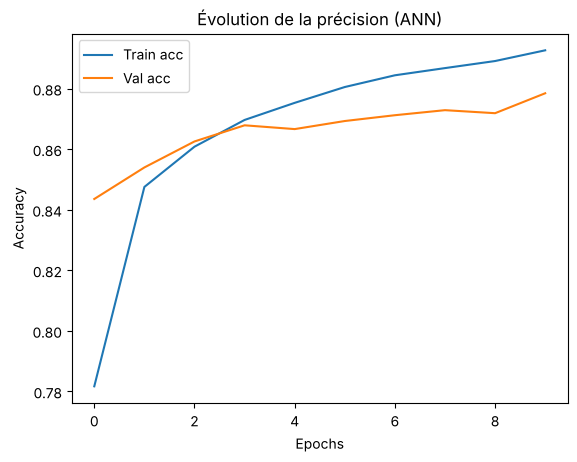

In [7]:
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

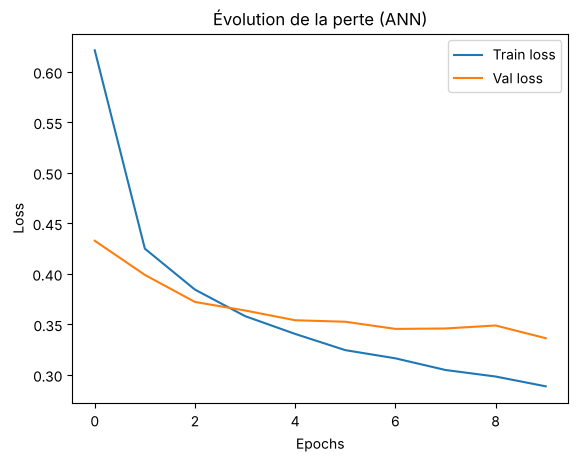

In [8]:
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.legend()
plt.title('Évolution de la perte (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

### Réponses
1. **Pourquoi ReLU ?** Elle introduit la non-linéarité à très faible coût (`max(0, x)`), son gradient vaut 1 pour les entrées positives (pas d'évanouissement du gradient comme avec sigmoïde/tanh) et elle produit des activations parcimonieuses : l'apprentissage est plus rapide et plus stable.
2. **accuracy vs val_accuracy** : `accuracy` est calculée sur les 80 % d'images utilisées pour ajuster les poids (moyenne sur l'époque, Dropout actif) ; `val_accuracy` est calculée en fin d'époque sur les 20 % réservés (`validation_split=0.2`, soit 12 000 images) jamais vus pendant l'apprentissage. Ici, à la 10ᵉ époque : accuracy = 89,3 %, val_accuracy = 87,9 %. L'écart reste faible, le Dropout limite le surapprentissage.
3. **50 époques** : la précision d'entraînement continuerait de monter (au-delà de 95 %) alors que la validation plafonnerait autour de 89–90 % et que `val_loss` remonterait : surapprentissage. Il faut alors un `EarlyStopping` ou davantage de régularisation.

### Évaluation finale

In [9]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8715 - loss: 0.3609
Précision sur le test set : 0.8715000152587891


## Étape 4 — Introduction aux fonctions d'activation
Objectif : comparer les performances des fonctions sigmoïde, tanh, ReLU et LeakyReLU.

sigmoid    : 0.8603
tanh       : 0.8725
relu       : 0.8685
LeakyReLU  : 0.8725


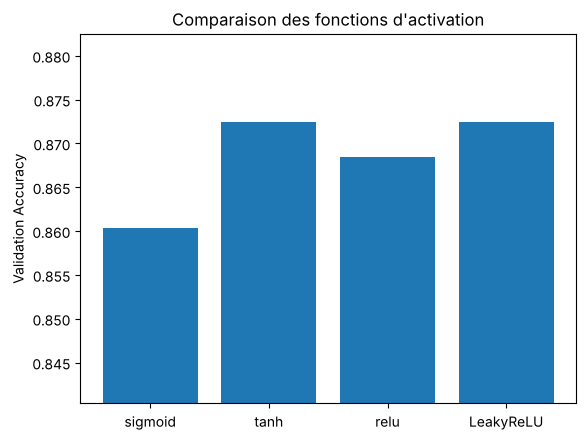

In [10]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(negative_slope=0.1),
    Dense(64),
    LeakyReLU(negative_slope=0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

for nom, acc in results.items():
    print(f"{nom:<10} : {acc:.4f}")

plt.bar(results.keys(), results.values())
plt.ylim(min(results.values()) - 0.02, max(results.values()) + 0.01)
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()

### Réponses
1. **Meilleure fonction** : après 5 époques, **tanh et LeakyReLU arrivent en tête à égalité (87,25 %)**, suivies de ReLU (86,85 %) puis de la sigmoïde (86,03 %), nettement derrière. Sur un réseau aussi peu profond (2 couches cachées) et un entraînement court, les écarts entre tanh, ReLU et LeakyReLU (≈ 0,4 point) sont de l'ordre du bruit aléatoire de l'initialisation ; en revanche la sigmoïde est clairement la plus lente à apprendre. Sur des réseaux plus profonds, l'avantage de la famille ReLU devient net.
2. **Sigmoïde et tanh dans les couches cachées** : elles saturent pour les grandes valeurs (|x| élevé), leur dérivée tend vers 0 (dérivée max de 0,25 pour la sigmoïde) et le gradient s'évanouit à travers les couches ; la sigmoïde n'est en plus pas centrée en 0 et toutes deux sont plus coûteuses (exponentielles). L'apprentissage est donc plus lent, surtout dans les réseaux profonds.
3. **LeakyReLU** : variante de ReLU qui laisse passer une petite pente pour les valeurs négatives (`0,1·x` ici) au lieu de 0. Le gradient n'est jamais nul, ce qui évite les « neurones morts » de ReLU (neurones bloqués à 0 qui n'apprennent plus).

## Étape 5 — Modèle CNN (Convolutional Neural Network)
### Création du modèle CNN

In [11]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Entraînement

In [12]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.7714 - loss: 0.6321 - val_accuracy: 0.8547 - val_loss: 0.4061
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.8586 - loss: 0.3927 - val_accuracy: 0.8761 - val_loss: 0.3432
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.8754 - loss: 0.3420 - val_accuracy: 0.8813 - val_loss: 0.3161
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.8873 - loss: 0.3097 - val_accuracy: 0.8929 - val_loss: 0.2917
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.8968 - loss: 0.2859 - val_accuracy: 0.8934 - val_loss: 0.2867
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.9021 - loss: 0.2678 - val_accuracy: 0.8967 - val_loss: 0.2754
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.9080 - loss: 0.2533 - val_accuracy: 0.9011 - val_loss: 0.2649
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.9132 - loss: 0.2371 - 

### Évaluation

In [13]:
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)
acc_cnn = test_acc

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9050 - loss: 0.2614
Précision CNN sur test set : 0.9049999713897705


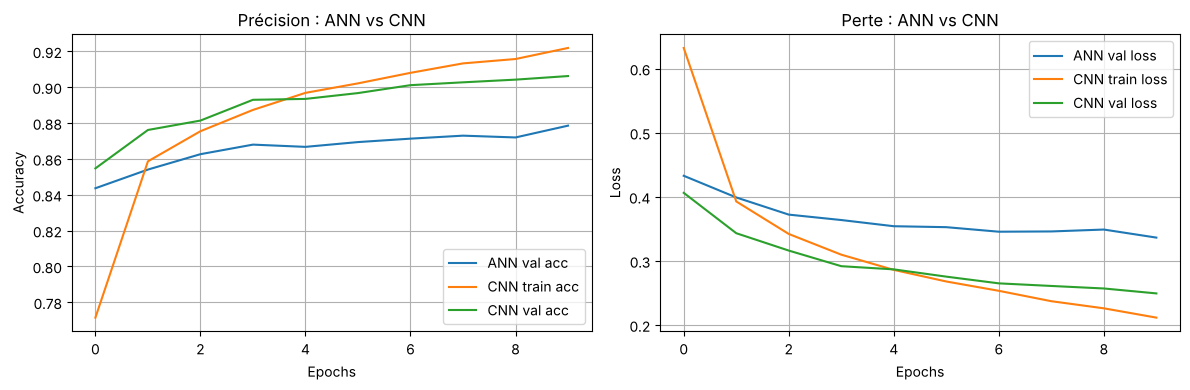

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['val_accuracy'], label='ANN val acc')
axes[0].plot(history_cnn.history['accuracy'], label='CNN train acc')
axes[0].plot(history_cnn.history['val_accuracy'], label='CNN val acc')
axes[0].set_title('Précision : ANN vs CNN')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)
axes[1].plot(history.history['val_loss'], label='ANN val loss')
axes[1].plot(history_cnn.history['loss'], label='CNN train loss')
axes[1].plot(history_cnn.history['val_loss'], label='CNN val loss')
axes[1].set_title('Perte : ANN vs CNN')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

### Réponses
1. **ANN vs CNN** : l'ANN aplatit l'image et relie chaque pixel à chaque neurone, en perdant la structure 2D. Le CNN applique des filtres convolutifs qui glissent sur l'image : il détecte des motifs locaux (bords, textures, formes) en conservant la disposition spatiale, avec des poids partagés sur toute l'image.
2. **Pourquoi le CNN est meilleur** : champs récepteurs locaux, partage des poids (moins de paramètres pour une même capacité), robustesse aux translations et apprentissage hiérarchique des caractéristiques (bords → motifs → parties d'objet). Résultat obtenu : **90,50 %** sur le test pour le CNN contre **87,15 %** pour l'ANN, soit +3,4 points.
3. **Rôle du Pooling** : réduire la taille des cartes de caractéristiques (ici ÷2 par dimension) en gardant la réponse la plus forte : moins de calculs et de paramètres en aval, tolérance aux petits décalages, et frein au surapprentissage.

## Étape 6 — Visualisation des performances

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


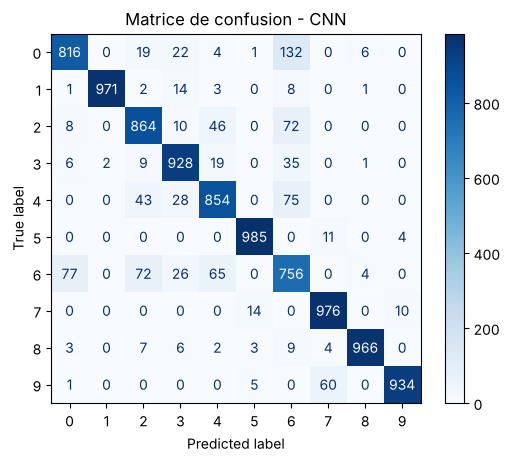

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matrice de confusion - CNN")
plt.show()

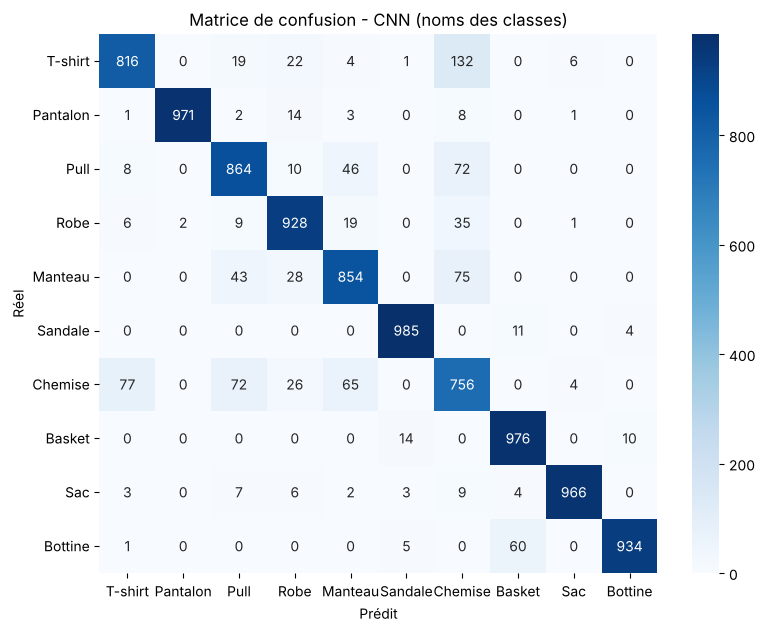

T-shirt   prédit comme Chemise   : 132
Chemise   prédit comme T-shirt   : 77
Manteau   prédit comme Chemise   : 75
Pull      prédit comme Chemise   : 72
Chemise   prédit comme Pull      : 72
Chemise   prédit comme Manteau   : 65

T-shirt   précision par classe : 81.60%
Pantalon  précision par classe : 97.10%
Pull      précision par classe : 86.40%
Robe      précision par classe : 92.80%
Manteau   précision par classe : 85.40%
Sandale   précision par classe : 98.50%
Chemise   précision par classe : 75.60%
Basket    précision par classe : 97.60%
Sac       précision par classe : 96.60%
Bottine   précision par classe : 93.40%


In [16]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.title('Matrice de confusion - CNN (noms des classes)')
plt.show()

paires = [(cm[i, j], class_names[i], class_names[j]) for i in range(10) for j in range(10) if i != j]
for n, reel, predit in sorted(paires, reverse=True)[:6]:
    print(f"{reel:<9} prédit comme {predit:<9} : {n}")

print()
for i, nom in enumerate(class_names):
    print(f"{nom:<9} précision par classe : {cm[i, i] / cm[i].sum():.2%}")

### Réponses
1. **Classes les plus confondues** : les confusions se concentrent sur les **hauts** :

| Classe réelle | Prédite comme | Nombre |
|---|---|---|
| T-shirt | Chemise | 132 |
| Chemise | T-shirt | 77 |
| Manteau | Chemise | 75 |
| Pull | Chemise | 72 |
| Chemise | Pull | 72 |
| Chemise | Manteau | 65 |

La **chemise** est la classe la plus difficile (75,6 % de bonnes réponses) car, à 28 × 28 pixels, elle partage la silhouette du T-shirt, du pull et du manteau (manches, col, coupe). À l'inverse, pantalon, sandale, basket et sac dépassent 96 %.
2. **Réduire ces erreurs** : CNN plus profond (davantage de filtres, BatchNormalization, couches Conv2D empilées avant chaque pooling), augmentation de données ciblée, entraînement plus long avec `EarlyStopping` et réduction du taux d'apprentissage (`ReduceLROnPlateau`), régularisation (Dropout), ensembles de modèles, ou pondération des classes difficiles (chemise) dans la perte.

## Étape 7 : Data Augmentation

In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

history_aug = cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.8629 - loss: 0.3763 - val_accuracy: 0.8989 - val_loss: 0.2717
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.8822 - loss: 0.3202 - val_accuracy: 0.8971 - val_loss: 0.2819
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 46ms/step - accuracy: 0.8870 - loss: 0.3050 - val_accuracy: 0.9025 - val_loss: 0.2622
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.8905 - loss: 0.2935 - val_accuracy: 0.9033 - val_loss: 0.2646
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - accuracy: 0.8944 - loss: 0.2856 - val_accuracy: 0.9006 - val_loss: 0.2698
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.8960 - loss: 0.2779 - val_accuracy: 0.9056 - val_loss: 0.2611
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - accuracy: 0.8997 - loss: 0.2697 - val_accuracy: 0.9019 - val_loss: 0.2652
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 43ms/step - accuracy: 0.9004 - loss: 0.2679 - 

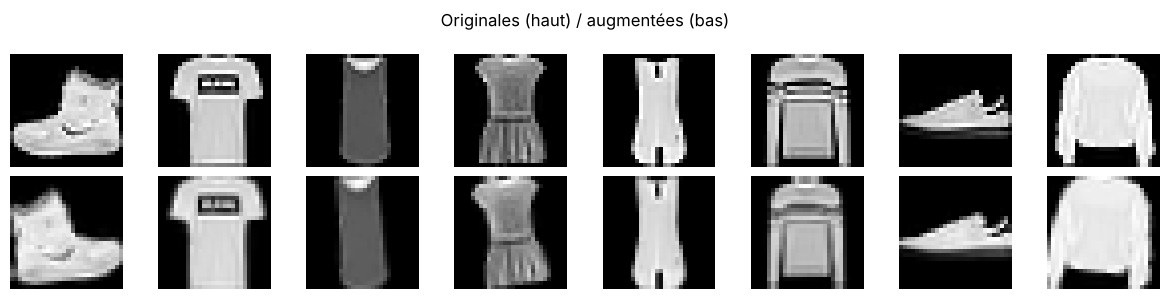

Précision CNN avant augmentation : 0.9050
Précision CNN après augmentation : 0.9110


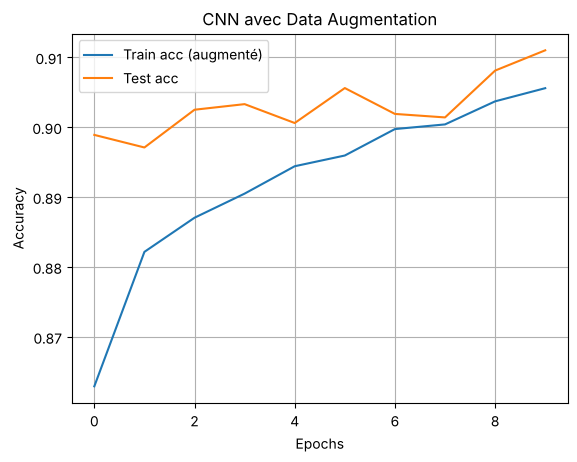

In [18]:
exemples = next(datagen.flow(X_train_cnn[:8], y_train[:8], batch_size=8, shuffle=False))[0]
plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(X_train_cnn[i].squeeze(), cmap='gray')
    plt.axis('off')
    plt.subplot(2, 8, i + 9)
    plt.imshow(exemples[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.suptitle('Originales (haut) / augmentées (bas)')
plt.tight_layout()
plt.show()

loss_aug, acc_aug = cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Précision CNN avant augmentation : {acc_cnn:.4f}")
print(f"Précision CNN après augmentation : {acc_aug:.4f}")

plt.plot(history_aug.history['accuracy'], label='Train acc (augmenté)')
plt.plot(history_aug.history['val_accuracy'], label='Test acc')
plt.title('CNN avec Data Augmentation')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

### Réponses
1. **Intérêt de la Data Augmentation** : générer à la volée des variantes plausibles des images (rotations, zooms, retournements) pour augmenter artificiellement la diversité du jeu d'entraînement. Le modèle mémorise moins les exemples exacts, devient plus robuste aux variations de position et d'échelle, et généralise mieux. Ici, après 10 époques supplémentaires avec augmentation, la précision test passe de **90,50 % à 91,10 %** ; la précision d'entraînement (90,6 %) reste proche de celle du test, signe que le surapprentissage est maîtrisé.
2. **Transformations les plus efficaces pour Fashion-MNIST** : le retournement horizontal (un vêtement reste le même vu en miroir), de petites translations (`width_shift_range`, `height_shift_range`), un léger zoom et de petites rotations (±10°). À éviter : le retournement vertical (une chaussure à l'envers n'existe pas dans les données réelles) et les fortes rotations, car les images du dataset sont toutes centrées et droites.

## Rapport — synthèse
| Modèle | Paramètres | Précision test |
|---|---|---|
| ANN (Dense 128 → Dropout → Dense 64) | 109 386 | 87,15 % |
| CNN (2 × Conv2D + MaxPooling) | 225 034 | 90,50 % |
| CNN + Data Augmentation (10 époques supplémentaires) | 225 034 | 91,10 % |

### Analyse personnelle
Sur Fashion-MNIST, le réseau dense plafonne à **87,15 %** sur le test, tandis que le CNN atteint **90,50 %** avec seulement deux couches convolutives, et **91,10 %** après un entraînement complémentaire avec augmentation de données. Le gain confirme l'intérêt des convolutions pour exploiter la structure spatiale des images. La comparaison des activations place tanh et LeakyReLU en tête (87,25 %), ReLU juste derrière et la sigmoïde nettement en retrait, ce qui illustre l'effet de saturation des gradients. La matrice de confusion montre que les erreurs restantes portent presque toutes sur les hauts (T-shirt, chemise, pull, manteau), la chemise n'étant reconnue qu'à 75,6 %.
Difficultés rencontrées : le temps d'entraînement du CNN sur CPU (≈ 15 s par époque, ≈ 20 s avec augmentation), la variabilité des résultats d'une exécution à l'autre qui rend les petits écarts entre activations peu significatifs, et le fait que l'étape 7 poursuit l'entraînement du même CNN, ce qui mêle l'effet de l'augmentation et celui des époques supplémentaires.
Pistes d'amélioration : CNN plus profond (blocs Conv2D-Conv2D-MaxPooling, BatchNormalization, 64–128 filtres), `EarlyStopping` et `ReduceLROnPlateau`, augmentation par translations (`width_shift_range`, `height_shift_range`), davantage d'époques, et pondération ou suréchantillonnage des classes de hauts les plus confondues.